<a href="https://colab.research.google.com/github/aliciamathias/concreto-resistencia-a-compressao/blob/main/Concreto_Apresenta%C3%A7%C3%A3o_Apresentar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 1 - Contexto dos Dados
*A resistência à compressão do concreto é uma das propriedades fundamentais na engenharia civil e construção de infraestruturas. Tradicionalmente, o teste laboratorial de resistência requer períodos de cura (como 28 dias), o que torna o processo de controle de qualidade demorado e oneroso. O comportamento do concreto depende de uma combinação complexa e não-linear de seus componentes (cimento, agregados, água, aditivos) e do tempo de cura.*

## -- Objetivo Principal
Desenvolver e avaliar modelos de Machine Learning (Regressão) capazes de estimar com precisão a resistência à compressão do concreto com base na sua composição e idade, permitindo:

Antecipar a resistência esperada sem aguardar o ciclo completo de cura laboratorial;
Oferecer suporte à tomada de decisões em controle de qualidade.

# Parte 2 - Preparação inicial


Nesta etapa, preparamos o ambiente de execução através de bibliotecas importadas:
- **Importação de bibliotecas:** ferramentas de manipulação (`pandas`, `numpy`), visualização (`matplotlib`, `seaborn`) e modelagem (`scikit-learn`);


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn import metrics

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Sucesso! As Bibliotecas foram instaladas")


Sucesso! As Bibliotecas foram instaladas


# Parte 3 - Entendimento dos Dados (EDA)

O objetivo desta etapa é explorar o conjunto de dados para compreender suas características estruturais e estatísticas:
- **Dimensões e tipos:** formato da base (linhas $\times$ colunas) e tipos de variáveis (numéricas contínuas / discretas);
- **Qualidade dos dados:** identificação de valores nulos, registros ausentes ou duplicidades;
- **Estatística descritiva:** análise de medidas de tendência central (média, mediana), dispersão (desvio padrão, variância) e quartis;
- **Distribuições e correlações:** análise de histogramas, matriz de correlação entre os componentes e a variável alvo.

PS: Apesar do readcsv e .head estarem nessa parte do EDA, o mais comum é eles estarem na parte 2, que é a definição e configuração do ambiente. Entretanto saiba que a posição dele não afetá de forma significativa a execução do código, apenas a sua presença em si é necessária antes de qualquer código que necessite dos dados do arquivo.

=== Primeiras 5 linhas da informações ===


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


=== Informações Gerais (Colunas e Tipos) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Conc

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.166408,73.894854,54.187379,181.564854,6.203204,972.918932,773.579515,45.662136,35.817961
std,104.507710,86.279340,63.995962,21.355663,5.973035,77.753954,80.175801,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.300000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


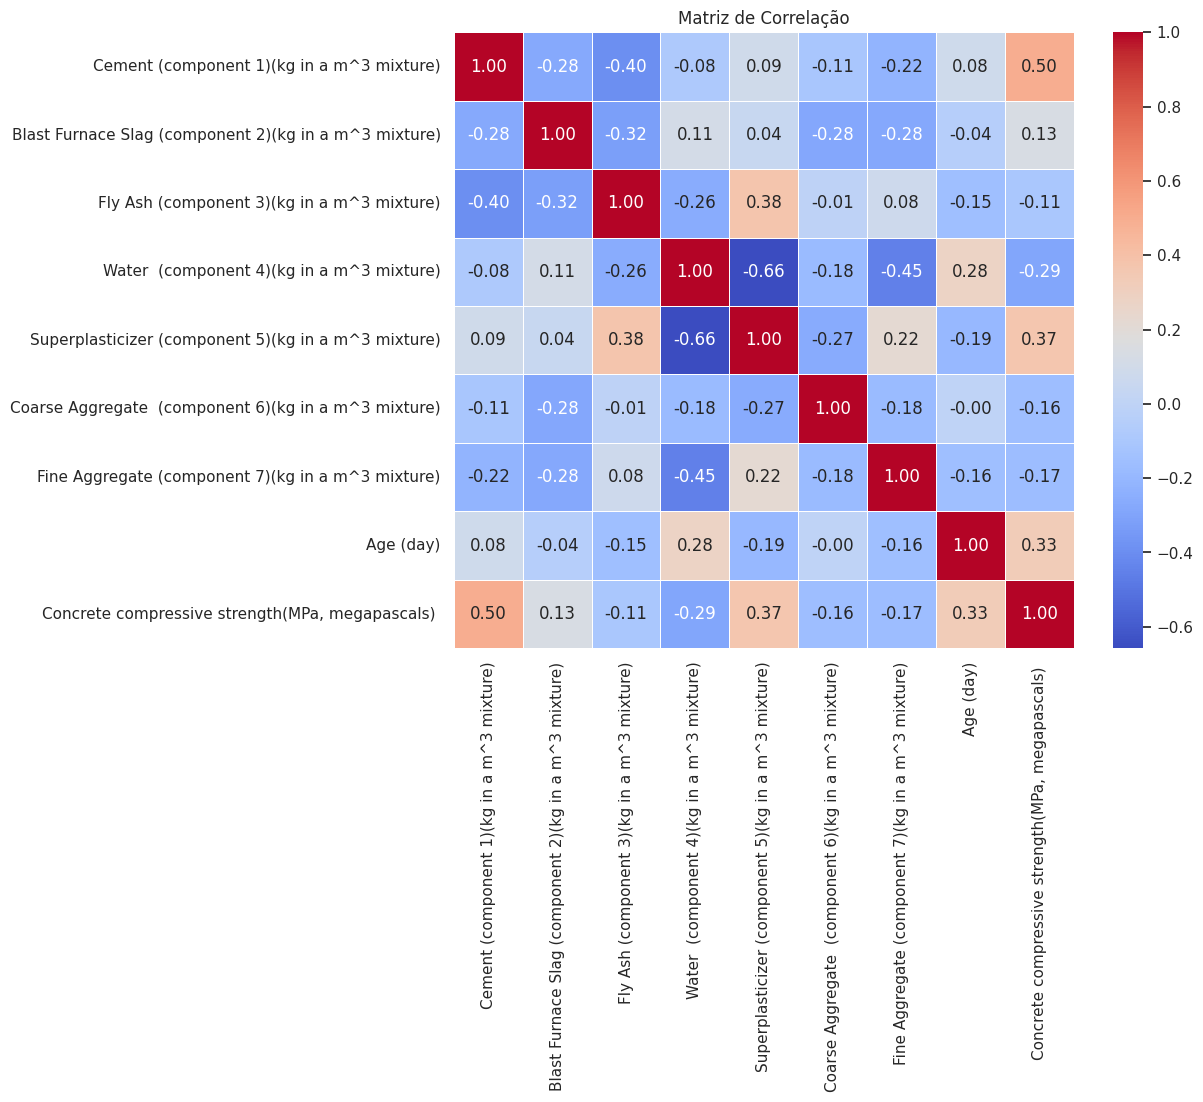

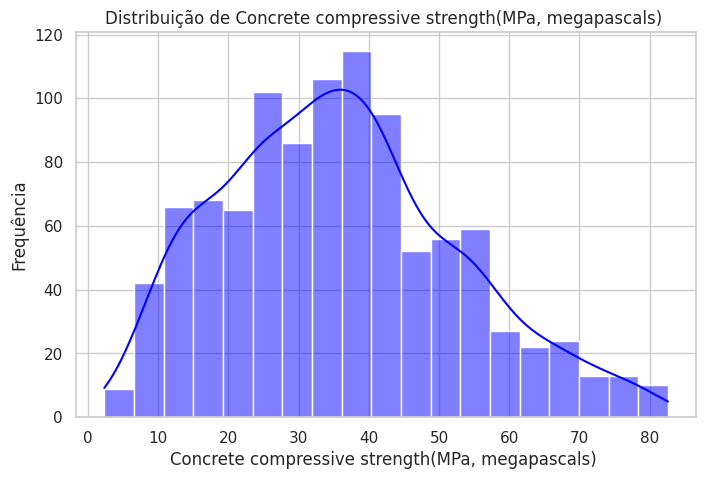

In [ ]:
df = pd.read_csv('/content/sample_data/Concrete_Data.csv')

print("=== Primeiras 5 linhas da informações ===")
display(df.head())

print("=== Informações Gerais (Colunas e Tipos) ===")
df.info()

print("\n === quantidade de Valores Nulos por Colunas ===")
print(df.isnull().sum())

print("\n === Estatíticas Descritivas ===")
display(df.describe())

# Parte da Análise de Distribuição e Correlação
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlação")
plt.show()

#Parte do Histograma da variável alvo (a ultima coluna é a resistência do concreto)
target_col = df.columns[-1]
plt.figure(figsize=(8,5))
sns.histplot(df[target_col], kde=True, color="blue")
plt.title(f"Distribuição de {target_col}")
plt.xlabel(target_col)
plt.ylabel("Frequência")
plt.show()

# Parte 4 - Preparação dos Dados

Antes de alimentar os algoritmos de aprendizado, realizamos o pré-processamento para garantir que os dados estejam no formato adequado:
- **Engenharia de variáveis (Feature Engineering):** criação de novas métricas (por exemplo, razão água/cimento), se aplicável;

In [ ]:
#Tratamento para impedir linhas duplicadas
print(f"Linhas antes da remoção de duplicatas: {len(df)}")
df = df.drop_duplicates()
print(f"Linhas após a remoção das duplicatas: {len(df)}")

#Nomeação das colunas para facilitar o entendimento
novos_nomes = {
    df.columns[0]:  'Cimento',
    df.columns[1]: 'Escoria_Alto_Forno',
    df.columns[2]: 'Cinza_Volante',
    df.columns[3]: 'Agua',
    df.columns[4]: 'SuperPlastificante',
    df.columns[5]: 'Agregrado_Graudo',
    df.columns[6]: 'Agregado_Miudo',
    df.columns[7]: 'Idade',
    df.columns[8]: 'Resistencia'
}

# Parte da Engenharia de Recursos (Feature Engineering)
# A razão água/cimento (Water-to-Cement ratio) é um indicador clássico da resistência do concreto.
# Para evitar divisão por zero, adicionamos uma pequena constante caso haja cimento zerado (embora improvável).
df = df.rename(columns = novos_nomes)

df['Razao_Agua_Cimento'] = df ['Agua'] / (df['Cimento'] + 1e-5)

print("\n Novas Colunas e Tipos após a preparação: ")
display(df.head())

Linhas antes da remoção de duplicatas: 1030
Linhas após a remoção das duplicatas: 1005

 Novas Colunas e Tipos após a preparação: 


,Cimento,Escoria_Alto_Forno,Cinza_Volante,Agua,SuperPlastificante,Agregrado_Graudo,Agregado_Miudo,Idade,Resistencia,Razao_Agua_Cimento
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,0.300000
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89,0.300000
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27,0.685714
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,0.685714
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30,0.966767


# Parte 5 - Divisão Treino e Teste

Para garantir uma avaliação justa e evitar o vazamento de dados (*data leakage*):
- Separação entre a matriz de variáveis preditoras ($X$) e o vetor da variável alvo ($y$);
- Particionamento em conjunto de **Treino** (para ajuste dos modelos) e **Teste** (para validação final independente);
- Fixação da semente de aleatoriedade (`random_state`) para assegurar a reprodutibilidade dos experimentos.

In [ ]:
x = df.drop(columns=['Resistencia'])
y = df['Resistencia']

#divisão do conjunto de dados em treino (80%) e teste (20%)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

print("=== Dimensões dos Conjuntos ===")
print(f"Treino (X_train): {x_train.shape} | Alvo (y_train): {y_train.shape}")
print(f"Teste (X_test): {x_test.shape} | Alvo(y_test.shape): {y_test.shape}")

=== Dimensões dos Conjuntos ===
Treino (X_train): (804, 9) | Alvo (y_train): (804,)
Teste (X_test): (201, 9) | Alvo(y_test.shape): (201,)


# Parte 6 - Modelagem

Nesta etapa, diferentes algoritmos de regressão são treinados e comparados:
- **Baseline:** modelo linear simples (como Regressão Linear) para servir de linha de base comparativa;
- **Modelos não-lineares e Ensembles:** algoritmos baseados em árvores de decisão (Random Forest, Gradient Boosting), que capturam relações complexas entre as variáveis;
- **Validação Cruzada ($K$-Fold):** avaliação robusta para verificar a consistência dos modelos e prevenir sobreajuste (*overfitting*);


In [ ]:
modelos= {
    "Regressão Linear": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("=== Avaliação por Validação Cruzada (Métrica de Treino) ===")
for nome, modelo in modelos.items():

    scores = cross_val_score(modelo,x_train, y_train, cv=kf,  scoring='neg_mean_absolute_error')
    mae_scores = -scores
    print(f"{nome:20} --> MAE MÈDIO: {mae_scores.mean():.4f} (+/- {mae_scores.std():.4f})")

for nome, modelo in modelos.items():
    modelo.fit(x_train, y_train)

print("\n Os modelos foram treinados com sucesso e estão prontos para avaliação final")

=== Avaliação por Validação Cruzada (Métrica de Treino) ===
Regressão Linear     --> MAE MÈDIO: 8.0411 (+/- 0.0725)
Random Forest        --> MAE MÈDIO: 3.7198 (+/- 0.2177)
Gradient Boosting    --> MAE MÈDIO: 3.7661 (+/- 0.2046)

 Os modelos foram treinados com sucesso e estão prontos para avaliação final


# Parte 7 - Avaliação Final

Com o modelo campeão selecionado, avaliamos sua performance no conjunto de teste independente:
- **Métricas de Regressão:**
  - **$R^2$ (Coeficiente de Determinação):** proporção da variância explicada pelo modelo;
  - **RMSE (Raiz do Erro Quadrático Médio):** penaliza grandes desvios e mede a magnitude média do erro na mesma unidade da variável alvo;
  - **MAE (Erro Médio Absoluto):** erro médio linear das previsões;
- **Análise de Resíduos:** inspeção gráfica dos erros para checar as normalidades de resíduos- **Importância das Variáveis (*Feature Importance*):** identificação dos fatores com maior peso na resistência à compressão.

=== Métricas de Avaliação Final (Conjunto de Teste) ===
R² : 0.9203
RMSE: 4.8748
MAE: 3.3385



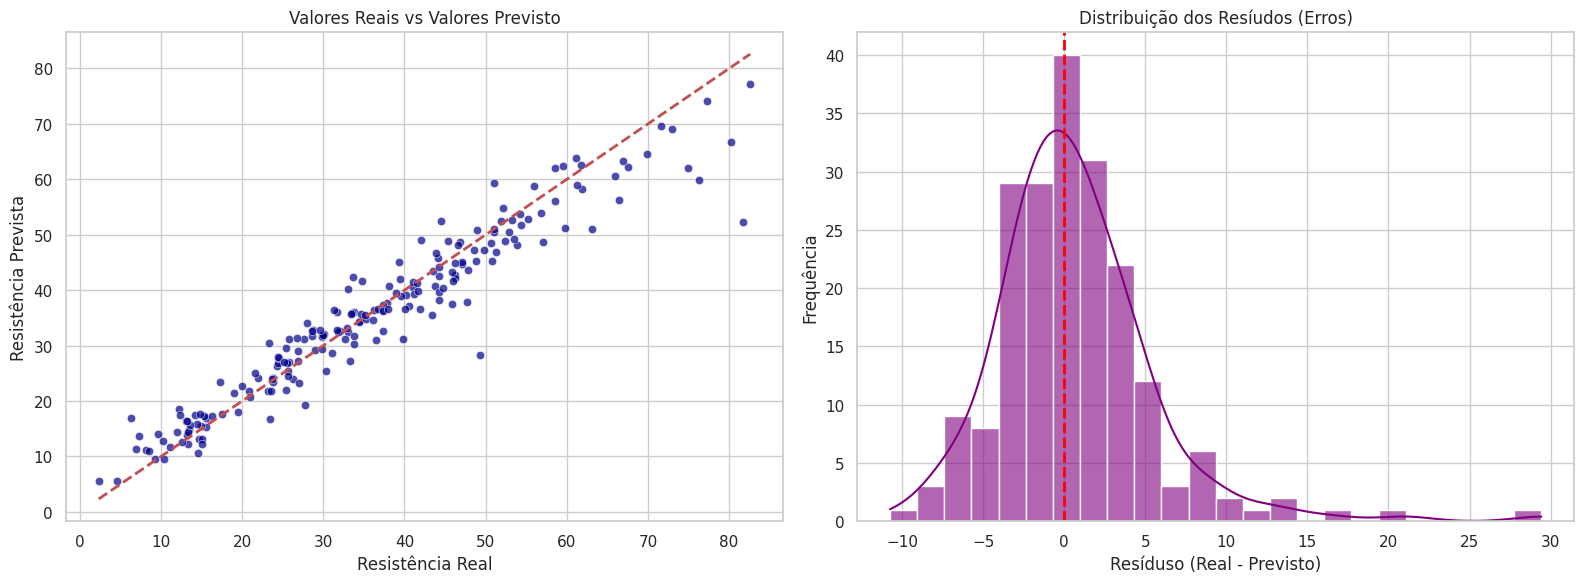

/tmp/ipykernel_2959/71234002.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancias[indices], y=x.columns[indices], palette="viridis")


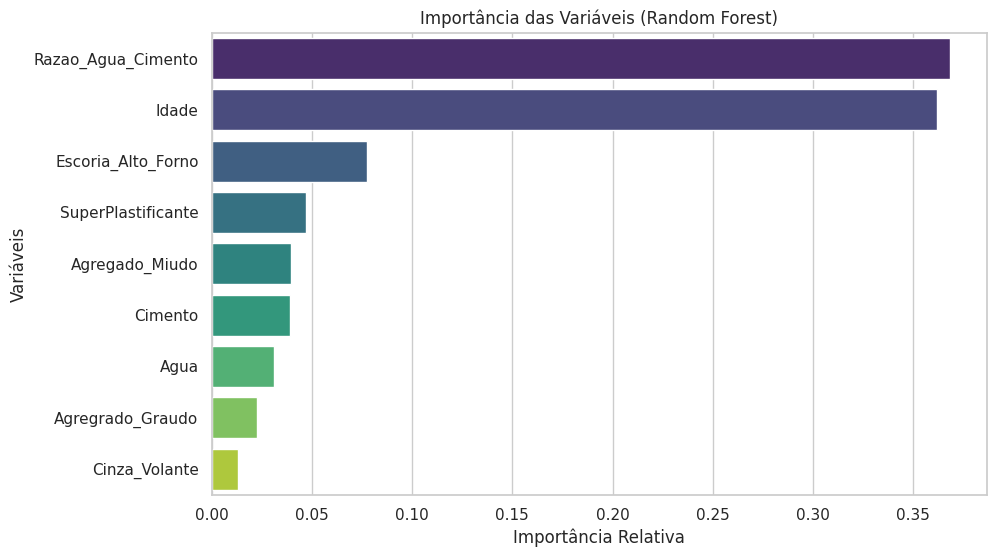

In [ ]:
# Aqui se define o melhor modelo que saiu nos treinos ( nesse caso o Random Forest será usado apenas para continuar o projeto)
# ps: tanto o gradient boosting quanto o Random forest são apenas 0,04 de difereça
melhor_modelo = modelos ["Random Forest"]

y_pred = melhor_modelo.predict(x_test)

r2 = metrics.r2_score(y_test, y_pred)
rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
mae = metrics.mean_absolute_error(y_test, y_pred)

print(f"=== Métricas de Avaliação Final (Conjunto de Teste) ===")
print(f"R² : {r2:.4f}")#<-- Coeficiente de Determinação
print(f"RMSE: {rmse:.4f}")#<--- Raiz do erro quadrático médio
print(f"MAE: {mae:.4f}\n")#<---- Erro Médio Absoluto

#Analise de Resíduos
residuos = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# parte aonde é mostrado o gráfico real vs o previsto
sns.scatterplot(x=y_test, y=y_pred, ax=axes[0], color="darkblue", alpha=0.7)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title("Valores Reais vs Valores Previsto")
axes[0].set_xlabel("Resistência Real")
axes[0].set_ylabel("Resistência Prevista")

#aqui é o gráfico de distribuição dos resíduos
sns.histplot(residuos, kde=True, ax=axes[1], color="purple", alpha=0.6)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title("Distribuição dos Resíduos (Erros)")
axes[1].set_xlabel("Resíduos (Real - Previsto)")
axes[1].set_ylabel("Frequência")

plt.tight_layout()
plt.show()

importancias= melhor_modelo.feature_importances_
indices = np.argsort(importancias)[::-1]

plt.figure(figsize=(10,6))
sns.barplot(x=importancias[indices], y=x.columns[indices], palette="viridis")
plt.title("Importância das Variáveis (Random Forest)")
plt.xlabel("Importância Relativa")
plt.ylabel("Variáveis")
plt.show()

# Parte 8 - Conclusão

- **Resultado:** o Random Forest apresentou o melhor desempenho (MAE médio de 3,72 MPa na validação cruzada, contra 8,04 da Regressão Linear). No conjunto de teste, obteve R² de 0,9203, RMSE de 4,87 MPa e MAE de 3,34 MPa, ou seja, explica cerca de 92% da variação da resistência e erra em média cerca de 3,3 MPa.
- **Modelos de árvores:** Random Forest e Gradient Boosting tiveram desempenho equivalente (diferença menor que o desvio da validação cruzada). A escolha do Random Forest se deu pelo menor MAE médio.
- **Generalização:** o erro no teste ficou próximo do erro da validação cruzada, sem sinal de sobreajuste.
- **Limitações:** base com 1005 amostras após a remoção de duplicatas; RMSE maior que o MAE indica erros pontuais maiores; não foi feito ajuste de hiperparâmetros; o modelo não substitui o ensaio de laboratório.
- **IA generativa** foi usada para melhor compreendimento e auxílio na conclusão da atividade.

